# 2D Poisson equation on the unit square

Solves the elliptic PDE
$$
-\nabla^2 u = f, \qquad \mathbf{x} \in \Omega = (0,1)^2, \qquad u = 0 \text{ on } \partial\Omega,
$$
where the source $f$ consists of a positive and a negative Gaussian bump (think of a heat source and a heat sink; $u$ is then the steady state temperature of the heat equation with the same source). There is no time and hence no initial condition, only the boundary condition.

With the 5-point Laplacian $L$ the PDE becomes the sparse linear system $-L \mathbf{u} = \mathbf{f}$, which we solve directly.

In [1]:
import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import spsolve
import matplotlib.pyplot as plt

In [2]:
def laplacian_2d(N, h):
    """5-point finite difference Laplacian on an N x N grid of interior
    nodes of the unit square, with zero Dirichlet boundary conditions.
    Unknowns are ordered row by row (x fastest)."""
    e = np.ones(N)
    D2 = sp.diags([e[:-1], -2 * e, e[:-1]], [-1, 0, 1]) / h**2
    I = sp.identity(N)
    return (sp.kron(I, D2) + sp.kron(D2, I)).tocsc()

In [3]:
# grid of N x N interior nodes on the unit square Omega = (0,1)^2
N = 60
h = 1.0 / (N + 1)
x = np.linspace(h, 1 - h, N)
X, Y = np.meshgrid(x, x)
L = laplacian_2d(N, h)
print(f"N = {N}, h = {h:.4f}, number of unknowns = {N**2}")

N = 60, h = 0.0164, number of unknowns = 3600


In [4]:
# source: a positive and a negative Gaussian bump
f = (100 * np.exp(-((X - 0.3) ** 2 + (Y - 0.6) ** 2) / (2 * 0.07**2))
     - 60 * np.exp(-((X - 0.7) ** 2 + (Y - 0.3) ** 2) / (2 * 0.1**2))).ravel()

u = spsolve(-L, f)
print(f"max |u| = {np.abs(u).max():.4f}")

max |u| = 0.7237


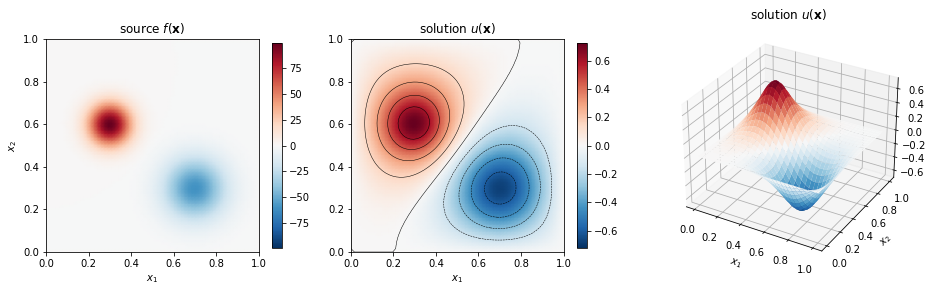

In [5]:
def with_boundary(u):
    """Embed interior values in an (N+2) x (N+2) array with zero boundary values."""
    U = np.zeros((N + 2, N + 2))
    U[1:-1, 1:-1] = u.reshape(N, N)
    return U


xb = np.linspace(0, 1, N + 2)


Ub, Fb = with_boundary(u), with_boundary(f)
Xb, Yb = np.meshgrid(xb, xb)

fig = plt.figure(figsize=(13, 4))
ax1 = fig.add_subplot(1, 3, 1)
m = np.abs(Fb).max()
im1 = ax1.pcolormesh(xb, xb, Fb, cmap="RdBu_r", vmin=-m, vmax=m, shading="gouraud")
ax1.set_aspect("equal")
ax1.set_title("source $f(\\mathbf{x})$")
ax1.set_xlabel("$x_1$")
ax1.set_ylabel("$x_2$")
fig.colorbar(im1, ax=ax1, shrink=0.85)

ax2 = fig.add_subplot(1, 3, 2)
m = np.abs(Ub).max()
im2 = ax2.pcolormesh(xb, xb, Ub, cmap="RdBu_r", vmin=-m, vmax=m, shading="gouraud")
ax2.contour(xb, xb, Ub, levels=12, colors="k", linewidths=0.5)
ax2.set_aspect("equal")
ax2.set_title("solution $u(\\mathbf{x})$")
ax2.set_xlabel("$x_1$")
fig.colorbar(im2, ax=ax2, shrink=0.85)

ax3 = fig.add_subplot(1, 3, 3, projection="3d")
ax3.plot_surface(Xb, Yb, Ub, cmap="RdBu_r", vmin=-m, vmax=m, linewidth=0)
ax3.set_xlabel("$x_1$")
ax3.set_ylabel("$x_2$")
ax3.set_title("solution $u(\\mathbf{x})$")

fig.tight_layout()
fig.savefig("poisson_2d.png", dpi=200, bbox_inches="tight")
plt.show()